# K-Nearest Neighbors

<div style="background-color:#1e293b;padding:15px;border-left:6px solid #38bdf8;color:#e2e8f0">

The linear and logistic regression models you have built so far work the same way: they work out a set of weights from the training data, and then have no further use for it. Predictions come from the weights. This notebook introduces a model that does the opposite. It keeps the training data and answers every new question by asking "which rows in my data look most like this one?"

The idea is simple enough to state in a sentence, which makes it a good place to see something the linear models could not show you: how much a model's behavior depends on the <b>units</b> of your columns. You will build a k-nearest neighbors model that predicts a car's fuel efficiency, watch it fail for a reason that has nothing to do with the algorithm, and fix it.

</div>

---
## Step 1: A Model That Keeps Its Data

k-nearest neighbors makes a prediction in three steps:
1. **Measure how far the new row is from the training rows.**
2. **Take the `k` closest ones.**
3. **Average their target values. That average is the prediction.**

There is no equation being fitted, so `fit()` does almost nothing here: it stores the training data, and it may also build an index, a structure that lets the search find the closest rows without checking every training row one by one. All the real work happens at prediction time.

We will predict the fuel efficiency of cars, in miles per gallon, from six numbers describing each car.

> **Data source:** Auto MPG dataset (UCI Machine Learning Repository), distributed with this course as `auto_mpg.csv`. Download it from the course folder and place it in the same directory as this notebook.

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import root_mean_squared_error

RANDOM_SEED = 23

df = pd.read_csv('auto_mpg.csv')
# 6 cars have no horsepower value. Dropping them keeps this small demonstration focused on KNN;
# in a real project you would decide how to handle missing values deliberately.
df = df.dropna()

feature_cols = ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year']
X = df[feature_cols]
y = df['mpg']

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_SEED)
print(f"Training rows: {len(X_train)}, validation rows: {len(X_val)}")

X_train.describe().loc[['min', 'max']].T

Training rows: 274, validation rows: 118


,min,max
cylinders,3.0,8.0
displacement,68.0,455.0
horsepower,48.0,225.0
weight,1613.0,4997.0
acceleration,8.0,24.8
model_year,70.0,82.0


> **Note:** Look at the table before moving on. `weight` runs from about 1,600 to 5,000. `cylinders` runs from 3 to 8. Those columns are measured in completely different units.

---
## Step 2: KNN on raw data vs KNN on scaled data

We fit the same model twice. The first time on the raw columns. The second time inside a `Pipeline` that scales them first, so every column is expressed in standard deviations rather than pounds or cylinders.

A linear regression on the same six columns is included as a reference point, so the scores mean something.

In [10]:
knn_raw = KNeighborsRegressor(n_neighbors=5)
knn_raw.fit(X_train, y_train)

knn_scaled = Pipeline(steps=[
    ('scale', StandardScaler()),
    ('model', KNeighborsRegressor(n_neighbors=5)),
])
knn_scaled.fit(X_train, y_train)

linear = LinearRegression()
linear.fit(X_train, y_train)

for name, model in [('KNN, raw columns', knn_raw),
                    ('KNN, scaled columns', knn_scaled),
                    ('LinearRegression', linear)]:
    train_rmse = root_mean_squared_error(y_train, model.predict(X_train))
    val_rmse = root_mean_squared_error(y_val, model.predict(X_val))
    print(f"{name:<22} train RMSE {train_rmse:.2f}   validation RMSE {val_rmse:.2f}")

KNN, raw columns       train RMSE 3.57   validation RMSE 4.17
KNN, scaled columns    train RMSE 2.53   validation RMSE 2.92
LinearRegression       train RMSE 3.46   validation RMSE 3.42


> **Note:** Scaling changed the validation RMSE from 4.17 to 2.92, an improvement of about 30%. Nothing about the algorithm changed: it still finds five neighbors and averages their fuel efficiency. What changed is which five cars count as the neighbors.
>
> Note also where the raw version landed: 4.17, clearly worse than linear regression's 3.42. On the scaled columns, KNN reaches 2.92 and beats it. A model that looked like the wrong choice was actually the right choice with the wrong input.

---
## Step 3: What "Distance" Means Here

The default distance is **Euclidean distance**: subtract the two rows column by column, square each difference, add them up, take the square root. For two cars that differ by 400 pounds and 1 cylinder, that sum is `400^2 + 1^2`, which is 160,001. The cylinder contributes 1 part in 160,000.

So on the raw columns, "distance between two cars" is very nearly "difference in weight", because weight is the column with the biggest numbers. Scaling puts every column into the same units first, so each one gets a fair say.

Here is what that does to one specific car. `kneighbors` returns the distances and the row positions of the closest training rows; we ask for two because the closest row to a training car is normally the car itself.

In [11]:
car_names = df.loc[X_train.index, 'name']

# One specific car: the 1973 Ford Maverick
is_query = (car_names == 'ford maverick') & (X_train['model_year'] == 73)
query_pos = int(np.flatnonzero(is_query.to_numpy())[0])   # flatnonzero: positions where the mask is True
query = X_train.iloc[[query_pos]]

# Fit on train only, then transform. The query is a training row, so it uses the same scaler.
scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
query_scaled = scaler.transform(query)

nn_raw = KNeighborsRegressor(n_neighbors=2).fit(X_train, y_train)
nn_scaled = KNeighborsRegressor(n_neighbors=2).fit(X_train_scaled, y_train)

# kneighbors returns (distances, row positions). We ask for 2 neighbors and take the
# second, because the closest row to a training car is normally the car itself.
raw_match = nn_raw.kneighbors(query)[1][0, 1]
scaled_match = nn_scaled.kneighbors(query_scaled)[1][0, 1]


def car_profile(pos):
    """Name, mpg and the six features of one training car, as a single column."""
    return pd.concat([
        pd.Series({'name': car_names.iloc[pos], 'mpg': y_train.iloc[pos]}),
        X_train.iloc[pos],
    ])


pd.DataFrame({
    'query car': car_profile(query_pos),
    'nearest, raw columns': car_profile(raw_match),
    'nearest, scaled columns': car_profile(scaled_match),
})

,query car,"nearest, raw columns","nearest, scaled columns"
name,ford maverick,oldsmobile cutlass ciera (diesel),amc hornet
mpg,18.0,38.0,18.0
cylinders,6.0,6.0,6.0
displacement,250.0,262.0,232.0
horsepower,88.0,85.0,100.0
weight,3021.0,3015.0,2945.0
acceleration,16.5,17.0,16.0
model_year,73.0,82.0,73.0


> **Note:** Before scaling, the nearest car is the 1982 Oldsmobile, which gets 38 mpg. After scaling, it is the 1973 Hornet, which gets 18 mpg, matching the query car.
>
> The Oldsmobile is only 6 pounds lighter than the query car, while the Hornet is 76 pounds lighter. Because weight is measured in pounds, its differences are much larger numbers in the distance calculation than differences in years or cylinders. On raw columns, the Oldsmobile's nine-year gap in model year adds less to the distance than the Hornet's larger weight gap does, and the Oldsmobile ends up closer overall. Scaling reduces that imbalance and changes which car is closest.
>
> Fuel type and mpg are not inputs to the search. We look at mpg afterward only to judge the result: here the scaled neighbor has a much closer target value, and the validation RMSE improvement from 4.17 to 2.92 shows that scaling improved overall validation performance.

---
## Step 4: k Is the Complexity Dial

`k` decides how many neighbors vote. It is the model's main setting and the one this notebook tunes first; it behaves exactly like the complexity settings you have already tuned.

With `k=1`, each prediction copies the single closest car. On the training data that car is usually the row itself, so training error is usually zero. That zero is an expected consequence of the setting; by itself, it does not establish good generalization. A `k=1` model also reacts to every bump in the data. With a large `k`, every prediction averages a big crowd, and the model smooths away real structure along with the noise.

To see this, we hold a car fixed at its typical values (the median of every other column) and slide its weight from the lightest to the heaviest in the data, then plot what each model predicts.

k=1   predicts between 16.5 and 33.5 mpg, biggest single jump 6.50
k=5   predicts between 17.7 and 28.9 mpg, biggest single jump 1.70
k=40  predicts between 20.0 and 28.4 mpg, biggest single jump 0.44


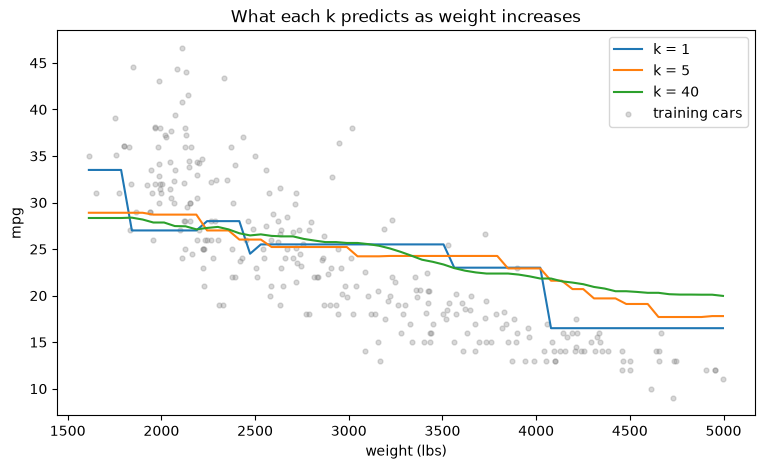

In [12]:
typical_car = X_train.median()
sweep = pd.DataFrame([typical_car] * 60)
sweep['weight'] = np.linspace(X_train['weight'].min(), X_train['weight'].max(), 60)

plt.figure(figsize=(9, 5))
for k in [1, 5, 40]:
    model = Pipeline(steps=[
        ('scale', StandardScaler()),
        ('model', KNeighborsRegressor(n_neighbors=k)),
    ]).fit(X_train, y_train)
    predictions = model.predict(sweep)
    plt.plot(sweep['weight'], predictions, label=f'k = {k}')
    biggest_jump = np.abs(np.diff(predictions)).max()
    print(f'k={k:<3} predicts between {predictions.min():.1f} and {predictions.max():.1f} mpg, '
          f'biggest single jump {biggest_jump:.2f}')

plt.scatter(X_train['weight'], y_train, s=12, alpha=0.3, color='gray', label='training cars')
plt.xlabel('weight (lbs)')
plt.ylabel('mpg')
plt.title('What each k predicts as weight increases')
plt.legend()
plt.show()

> **Note:** Increasing `k` makes the predictions change more gradually. The `k=1` line jumps in steps, some of them large: its biggest single jump between two neighboring points on this sweep is 6.5 mpg, because it copies one car at a time. At `k=5` the biggest jump is 1.70 mpg, and at `k=40` it is 0.44 mpg. Averaging more neighbors smooths the predictions.
>
> The gray dots are real training cars, and they differ from the swept car in their other columns too. Every training car above 4,000 lbs has 8 cylinders, while the swept car keeps the median of 4. So the distance between a line and the dots is not a prediction error, and this picture alone cannot tell you which `k` is best.
>
> In the vocabulary of bias and variance: small `k` is high variance, because predictions follow individual cars; large `k` moves toward high bias, because each prediction averages over more cars that are less similar to it. Whether the smoothing helps or hurts on new cars is a question for validation scores, which is the next step.

---
## Step 5: Choosing k with a Validation Curve

Fit one model per candidate `k`, score each on training and validation data, and plot both.

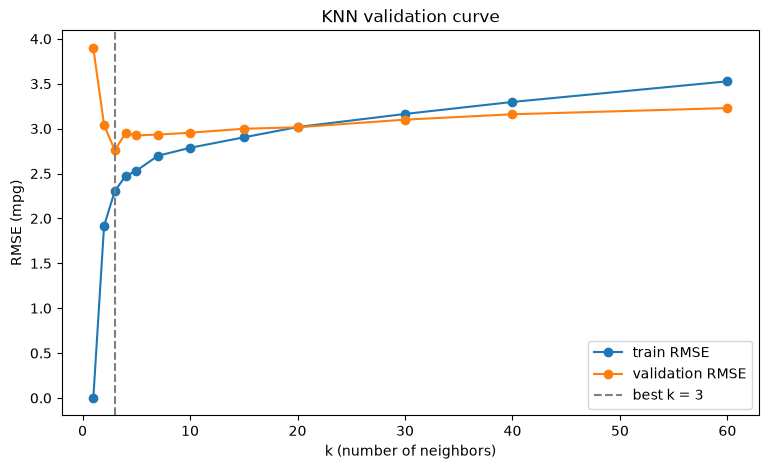

k=1   train RMSE 0.00   validation RMSE 3.90
k=2   train RMSE 1.92   validation RMSE 3.04
k=3   train RMSE 2.31   validation RMSE 2.76
k=4   train RMSE 2.47   validation RMSE 2.95
k=5   train RMSE 2.53   validation RMSE 2.92
k=7   train RMSE 2.70   validation RMSE 2.93
k=10  train RMSE 2.79   validation RMSE 2.95
k=15  train RMSE 2.90   validation RMSE 3.00
k=20  train RMSE 3.02   validation RMSE 3.01
k=30  train RMSE 3.16   validation RMSE 3.10
k=40  train RMSE 3.30   validation RMSE 3.16
k=60  train RMSE 3.53   validation RMSE 3.23


In [13]:
ks = [1, 2, 3, 4, 5, 7, 10, 15, 20, 30, 40, 60]
train_scores, val_scores = [], []

for k in ks:
    model = Pipeline(steps=[
        ('scale', StandardScaler()),
        ('model', KNeighborsRegressor(n_neighbors=k)),
    ]).fit(X_train, y_train)
    train_scores.append(root_mean_squared_error(y_train, model.predict(X_train)))
    val_scores.append(root_mean_squared_error(y_val, model.predict(X_val)))

# np.argmin returns the INDEX of the smallest value, so this picks the winning k
best_k = ks[np.argmin(val_scores)]

plt.figure(figsize=(9, 5))
plt.plot(ks, train_scores, 'o-', label='train RMSE')
plt.plot(ks, val_scores, 'o-', label='validation RMSE')
plt.axvline(best_k, color='gray', linestyle='--', label=f'best k = {best_k}')
plt.xlabel('k (number of neighbors)')
plt.ylabel('RMSE (mpg)')
plt.title('KNN validation curve')
plt.legend()
plt.show()

for k, tr, va in zip(ks, train_scores, val_scores):
    print(f"k={k:<3} train RMSE {tr:.2f}   validation RMSE {va:.2f}")

> **Note:** At `k=1` the training RMSE is 0.00, because each training car is its own nearest neighbor and the model returns the answer it was given. That zero is an expected consequence of the setting; by itself, it does not establish good generalization. The validation RMSE is what tells you about new cars, and at `k=1` it is 3.90, the worst on the list. This is the clearest example yet of why a training score cannot choose anything for you.
>
> Validation RMSE bottoms out at 2.76 with `k=3`, then rises slowly as `k` grows and the averaging gets too aggressive. Around the bottom the curve is bumpy: `k=4` scores 2.95, worse than both `k=3` (2.76) and `k=5` (2.92). With only 118 cars in the validation set, some of that bumpiness is probably just which cars happened to land in it, and a different split could reorder neighboring values of `k`. So treat the bottom of the curve as a region to pick from (roughly `k=3` to `k=10` here), not as one exact best value.
>
> From `k=20` onward the validation RMSE is slightly lower than the training RMSE (3.16 against 3.30 at `k=40`). That is not a bug. The two sets contain different cars, so either score can come out lower, and here the validation cars happen to be a little easier to predict at those settings.

---
## Step 6: Where KNN Struggles

KNN treats every column as equally important, because every column contributes to the distance in the same way. It has no way to learn that one column is useless. A linear model is different: it learns a separate coefficient for each column, so it can give an unhelpful column little influence.

To see what that costs, we add columns of pure random noise to the data. The noise contains no information about fuel efficiency whatsoever. We add the same noise columns to three different models and watch what each one does with them: this KNN model, a regularized linear model, and a decision tree.

> **Note:** The tree gets its detailed review soon. For now it only matters that it works in a completely different way from the other two, asking a sequence of threshold questions instead of measuring distance or summing weighted columns.

In [14]:
rng = np.random.default_rng(RANDOM_SEED)   # modern NumPy random generator, seeded for repeatability

# Ridge and the tree are kept at fixed settings here on purpose: we are watching how each
# model DEGRADES as noise is added, not deciding which of the three is best.
print(f"{'noise columns':>14} {'KNN':>9} {'Ridge':>9} {'DecisionTree':>14}")
for n_noise in [0, 2, 5, 10, 20, 50]:
    X_train_noisy, X_val_noisy = X_train.copy(), X_val.copy()
    for j in range(n_noise):
        X_train_noisy[f'noise_{j}'] = rng.normal(size=len(X_train_noisy))
        X_val_noisy[f'noise_{j}'] = rng.normal(size=len(X_val_noisy))

    row = []
    for model in [KNeighborsRegressor(n_neighbors=best_k), Ridge(alpha=1.0),
                  DecisionTreeRegressor(max_depth=5, random_state=RANDOM_SEED)]:
        pipe = Pipeline(steps=[('scale', StandardScaler()), ('model', model)])
        pipe.fit(X_train_noisy, y_train)
        row.append(root_mean_squared_error(y_val, pipe.predict(X_val_noisy)))
    print(f"{n_noise:>14} {row[0]:>9.2f} {row[1]:>9.2f} {row[2]:>14.2f}")

baseline = root_mean_squared_error(y_val, np.full(len(y_val), y_train.mean()))
print(f"\nfor scale: predicting the average mpg every time scores {baseline:.2f}")

 noise columns       KNN     Ridge   DecisionTree
             0      2.76      3.41           3.84
             2      3.60      3.41           3.90
             5      3.87      3.42           4.15
            10      4.24      3.46           4.00
            20      4.16      3.34           3.60
            50      5.20      3.98           3.52

for scale: predicting the average mpg every time scores 6.94


> **Note:** KNN degrades badly and immediately: two noise columns move validation RMSE from 2.76 to 3.60, and fifty push it to 5.20. For scale, simply predicting the average mpg for every car scores about 6.94, so at fifty noise columns KNN has given up most of what it knew.
>
> Ridge changes little through twenty noise columns, staying between 3.34 and 3.46, but its RMSE rises from 3.41 to 3.98 with fifty. Unlike KNN's distance, a linear model learns a separate coefficient for each column, so it can give an unhelpful column little influence. Ridge's penalty also discourages large coefficients, but it is not the main explanation here: plain `LinearRegression`, with no penalty at all, gives almost identical numbers in this experiment (you can check by swapping it in). The tree's column wanders between 3.52 and 4.15 with no clear trend in this run, which is the point: it is not systematically damaged the way KNN is here, because it never has to combine all the columns into a single number. It picks splits one column at a time, and a noise column simply loses most of those contests. This is one run at one random seed, not a guarantee that trees are immune to noise columns in general.
>
> This is the practical face of the **curse of dimensionality**. Every column contributes to a distance, and KNN has no way to discount one, so columns that carry nothing still get a vote on who counts as a neighbor. There is a deeper version of the same effect: each column you add spreads the same number of rows more thinly, so even useful columns are not free. On a large table an informative column usually pays for itself; on a small one it may not.
>
> The practical advice is to give this model a focused set of features you have a reason to trust, rather than everything the table happens to contain.

### The classification twin

Everything here applies unchanged to classification. `KNeighborsClassifier` finds the same `k` nearest rows and takes a majority vote instead of an average. Same distance, same scaling requirement, same meaning for `k`. You will use it in a later notebook.

---
## YOUR TURN

<div style="background-color:#1e293b;padding:15px;border-left:6px solid #38bdf8;color:#e2e8f0">

<b>Exercise: Two more dials</b>

The KNN you built gives all `k` neighbors an equal vote and measures distance the standard way. Both of those are settings you can change.

1. Refit at the winning `k` with <code>weights='distance'</code>, which makes closer neighbors count for more than distant ones. What happens to validation RMSE?

2. Refit at the winning `k` with <code>metric='manhattan'</code>, which adds up the absolute differences instead of squaring them. What happens to validation RMSE?

3. In two or three sentences: which of the changes you have made in this notebook mattered most, and why do you think that is?

</div>

In [ ]:
# YOUR TURN
# 1. Distance weighting:
#    - Pipeline with KNeighborsRegressor(n_neighbors=best_k, weights='distance')
#    - fit on X_train, print validation RMSE
# 2. Manhattan distance:
#    - Pipeline with KNeighborsRegressor(n_neighbors=best_k, metric='manhattan')
#    - fit, print validation RMSE
# 3. Your conclusions:
# Scaling the columns mattered most: validation RMSE went from 4.17 to 2.92,
# because a big column like weight no longer dominated the distance sum.
# Choosing k was the next important step (3.90 at k=1, 2.76 at k=3). Giving closer
# neighbors more weight only moved the score from 2.76 to 2.72, and Manhattan
# distance made it worse (3.24).
model = Pipeline(steps=[
        ('scale', StandardScaler()),
        ('model', KNeighborsRegressor(n_neighbors=best_k, weights='distance')),
    ]).fit(X_train, y_train)
val_rmse = root_mean_squared_error(y_val, model.predict(X_val))
print(f"distance-weighted KNN validation RMSE {val_rmse:.2f}")

model = Pipeline(steps=[
        ('scale', StandardScaler()),
        ('model', KNeighborsRegressor(n_neighbors=best_k, metric='manhattan')),
    ]).fit(X_train, y_train)
val_rmse = root_mean_squared_error(y_val, model.predict(X_val))
print(f"manhattan distance KNN validation RMSE {val_rmse:.2f}")


distance-weighted KNN validation RMSE 2.72
manhattan distance KNN validation RMSE 3.24


<details><summary><b>Click for Solution</b></summary>

```python
for label, settings in [('uniform, euclidean (baseline)', {}),
                        ('distance-weighted', {'weights': 'distance'}),
                        ('manhattan distance', {'metric': 'manhattan'})]:
    model = Pipeline(steps=[
        ('scale', StandardScaler()),
        ('model', KNeighborsRegressor(n_neighbors=best_k, **settings)),
    ]).fit(X_train, y_train)
    val_rmse = root_mean_squared_error(y_val, model.predict(X_val))
    print(f"{label:<30} validation RMSE {val_rmse:.2f}")
```

Distance weighting gives 2.72 against the baseline's 2.76: a small improvement on this split. By the same logic as the validation curve's wobble, do not trust it yet; check it with a re-split or a five-fold comparison before preferring it. Manhattan distance gives 3.24, clearly worse on this split, with a gap wide enough that it does not call for the same check here; that is a statement about this one comparison, not a general ranking between the two metrics.

Neither comes close to the change that mattered. Scaling moved validation RMSE from 4.17 to 2.92, and choosing `k` moved it from 3.90 at `k=1` to 2.76 at `k=3`. Both of those are large. The two settings in this exercise are fine-tuning on top of decisions that were already made correctly.

That ordering is the lesson worth keeping: get the input right first, then the main setting, and only then reach for the small dials.

</details>

---
## What You Should Be Able to Do Now

- Explain how k-nearest neighbors makes a prediction, and why its `fit` step does so little.
- State why KNN needs its features scaled, in terms of what distance actually measures.
- Read `k` as a bias-variance dial and choose it with a validation curve.
- Explain why zero training RMSE at `k=1` does not establish good generalization.
- Explain why uninformative columns hurt KNN more than they hurt a regularized linear model.
- Name the classification version of the model and what it does differently.